# 02 · Data Processing

## What this notebook does
In notebook 01 we learned what the data looks like and what is wrong with it. Here we turn those findings into
**one clean table**, with one row per hour of 2024, that the model can use. Each step below comes from a finding in 01.

| Step | Why (finding in 01) |
|---|---|
| 1 · Split the data in time | Everything learned from data must come from the training period only |
| 2 · Flag suspect hours | Vehicle counts collapse before outages (29 April) |
| 3 · Select neighbour cells | The most correlated cells form the junction's cross shape |
| 4 · Fill missing hours | 9% of hours are missing, including whole days |
| 5 · Add weather | Rain and snow slow traffic down |
| 6 · Add the calendar | Iftar effect, first holiday day differs, school days |
| 7 · Add fuel price events | Possible queues at petrol stations before price hikes |
| 8 · Save the dataset | Input for feature engineering (notebook 03) |

**Main rule:** this project aims for a **realistic** forecast, not the highest possible score. Whenever there is a choice,
the model only gets information that would really be available one hour before the forecast time.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.data import load_traffic, load_weather, load_fuel_events, TARGET_CELL, ROOT, FIG_DIR
from src.processing import (SPLITS, SUSPECT_RATIO, N_NEIGHBOURS, MAX_DIST_KM, MIN_COVERAGE, WEATHER_COLS,
                            wide_table, build_dataset, typical_profile)
from src.calendar_2024 import PUBLIC_HOLIDAYS

BLUE, ORANGE, GREY='#2E6FBA', '#D9822B', '#8A8F98'
plt.rcParams.update({
    'figure.dpi':110, 'savefig.dpi':300, 'savefig.bbox':'tight',
    'font.family':'serif', 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.grid':True, 'grid.color':'#E5E5E5', 'grid.linewidth':0.6,
})
def save(fig, name):
    fig.savefig(FIG_DIR/f'{name}.png')

traffic=load_traffic()
weather=load_weather()
fuel=load_fuel_events()
df, meta, cell_info=build_dataset(traffic, weather, fuel)
print(f'Dataset: {df.shape[0]:,} hours x {df.shape[1]} columns')

Dataset: 8,784 hours x 33 columns


## 1 · Split the data in time

> 🔍 **Why first?** Several later steps learn something from the data: the typical speed used to fill gaps, the normal
> vehicle count, and which neighbours are most correlated. If these were computed on the whole year, information from
> the test period would leak into the model. So we fix the split **before** anything else.

We use a split by calendar months:

| Part | Period | Use |
|---|---|---|
| Train | January – August | Fit the model and every value learned from data |
| Validation | September – October | Choose model settings, early stopping |
| Test | November – December | Final evaluation, used **once** at the end |

**Why months and not a 70/15/15 ratio?** Both are chronological, so neither leaks the future. A split by months is
easier to explain and to repeat ("the model was tested on November and December"), and it does not change when
rows are added or removed. A random split would be wrong for time series, because the model would see hours
right next to the test hours.

**One extra step for the modelling notebook:** a single test period can be lucky or unlucky. For choosing models we will
also use **walk-forward validation** inside January–October (train on months 1…n, validate on month n+1, repeat).
This shows whether a model is stable across seasons. The November–December test set stays untouched until the end.

In [2]:
summary=df.groupby('split', sort=False).agg(
    start=('split', lambda s: s.index.min().date()), end=('split', lambda s: s.index.max().date()),
    hours=('split', 'size'), usable_hours=('usable', 'sum'))
summary['usable_share']=(summary['usable_hours']/summary['hours']).round(3)
summary

,start,end,hours,usable_hours,usable_share
split,,,,,
train,2024-01-01,2024-08-31,5856,5292,0.904
val,2024-09-01,2024-10-31,1464,1463,0.999
test,2024-11-01,2024-12-31,1464,1249,0.853


**Findings.** The test period has the lowest share of usable hours, because of the outages in December.
Test results will be reported on usable hours only, and we will state this coverage in the paper.

## 2 · Flag suspect hours

> 🔍 **Why?** In 01 we saw that the vehicle count fades out before an outage (52 → 27 → 10 → 7 → 2 → 1 vehicles on
> 28–29 April). Speeds measured from a handful of vehicles are not reliable. A fixed limit such as "fewer than 10
> vehicles" does not work well, because a normal night has far fewer vehicles than a normal afternoon. So we compare each
> hour with what is **normal for that weekday and hour**.

**Rule:** an hour is *suspect* if its vehicle count is below **10%** of the typical count for the same weekday and hour
(typical = median of the training period).

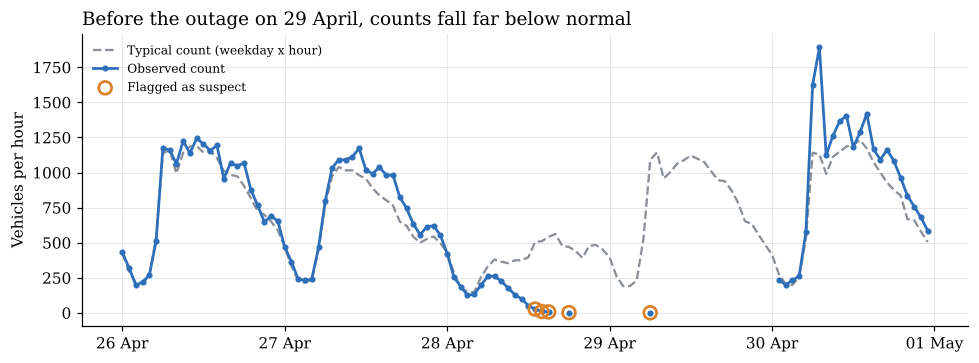

Suspect hours at Mahmutbey: 11


,split,speed_raw,vehicles,typical
DATE_TIME,,,,
2024-02-24 00:00:00,train,NaN,29.0,470.0
2024-03-17 19:00:00,train,NaN,37.0,440.0
2024-04-28 13:00:00,train,NaN,27.0,505.0
2024-04-28 14:00:00,train,NaN,10.0,511.0
2024-04-28 15:00:00,train,NaN,7.0,542.0
2024-04-28 18:00:00,train,NaN,2.0,470.0
2024-04-29 06:00:00,train,NaN,1.0,1088.0
2024-11-03 05:00:00,test,NaN,15.0,255.0
2024-11-11 21:00:00,test,NaN,11.0,635.0


In [3]:
veh=wide_table(traffic, 'NUMBER_OF_VEHICLES')[TARGET_CELL]
prof=typical_profile(veh)
typical=pd.Series(prof.reindex(list(zip(veh.index.dayofweek, veh.index.hour))).values, index=veh.index)

window=slice('2024-04-26', '2024-04-30')
fig, ax=plt.subplots(figsize=(9, 3.4))
ax.plot(typical[window], color=GREY, lw=1.5, ls='--', label='Typical count (weekday x hour)')
ax.plot(veh[window], color=BLUE, lw=1.8, marker='o', ms=3, label='Observed count')
sus=df.loc[window].query('suspect==1').index
ax.scatter(sus, veh[sus], s=70, facecolor='none', edgecolor=ORANGE, lw=1.8, zorder=3, label='Flagged as suspect')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_ylabel('Vehicles per hour')
ax.set_title('Before the outage on 29 April, counts fall far below normal', loc='left')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, 'fig11_suspect_hours'); plt.show()

print(f'Suspect hours at Mahmutbey: {df["suspect"].sum()}')
display(df.query('suspect==1')[['split', 'speed_raw']].assign(vehicles=veh[df['suspect']==1], typical=typical[df['suspect']==1].round(0)))

**Findings.** Only 11 hours are flagged, so the rule is strict and removes clear problems only. Low traffic on holidays
(for example 1 January) is **not** flagged, because it is real traffic, not a measurement problem.
One flagged hour, 17 March 19:00, is an iftar hour, so part of the drop may be real. We still keep one simple rule
for all hours and mention this case.

> ➡️ **What it means for the model:** suspect hours are treated like missing hours. They are never used as a target
> in training or testing.

## 3 · Select neighbour cells

> 🔍 **Why?** One goal of this project is to test whether nearby road cells improve the forecast. We need a clear and
> repeatable rule for choosing them, not a hand-picked list.

**Rule:** among cells within **3 km** that have at least **90%** coverage, take the **6** cells whose speed is most
correlated with Mahmutbey **in the training period**. Using only training data matters: the choice of neighbours is
also something "learned" from data.

,feature,LATITUDE,LONGITUDE,dist_km,coverage,corr_train
GEOHASH,,,,,,
sxk3xd,nb1,41.059,28.812,0.611,0.913,0.964
sxk985,nb2,41.064,28.834,1.844,0.912,0.959
sxk3xg,nb3,41.064,28.823,0.922,0.912,0.943
sxk3x7,nb4,41.064,28.801,0.922,0.913,0.942
sxk3x9,nb5,41.053,28.812,1.223,0.912,0.937
sxk3x8,nb6,41.048,28.812,1.834,0.913,0.921


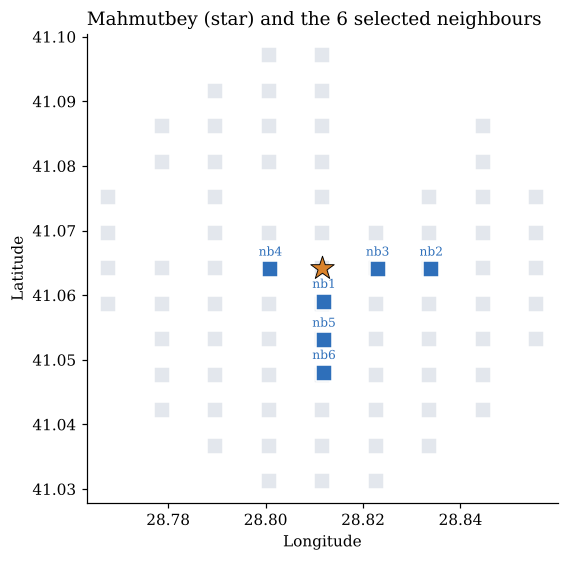

In [4]:
nb=meta['neighbours']
table=cell_info.loc[nb, ['LATITUDE', 'LONGITUDE', 'dist_km', 'coverage', 'corr_train']].round(3)
table.insert(0, 'feature', [f'nb{i}' for i in range(1, len(nb)+1)])
display(table)

lat0, lon0=cell_info.loc[TARGET_CELL, ['LATITUDE', 'LONGITUDE']]
near=cell_info.query('dist_km<=4')
fig, ax=plt.subplots(figsize=(6, 5.2))
ax.scatter(near['LONGITUDE'], near['LATITUDE'], s=120, marker='s', color='#E3E7ED', edgecolor='white')
ax.scatter(table['LONGITUDE'], table['LATITUDE'], s=120, marker='s', color=BLUE, edgecolor='white')
for name, row in table.iterrows():
    ax.annotate(row['feature'], (row['LONGITUDE'], row['LATITUDE']), xytext=(0, 9), textcoords='offset points',
                ha='center', fontsize=8, color=BLUE)
ax.scatter(lon0, lat0, s=260, marker='*', color=ORANGE, edgecolor='black', linewidth=0.6, zorder=3)
ax.set_aspect(1/np.cos(np.radians(lat0)))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.grid(False)
ax.set_title('Mahmutbey (star) and the 6 selected neighbours', loc='left')
fig.tight_layout(); save(fig, 'fig12_neighbours'); plt.show()

**Findings.** The six neighbours are the same cells we saw in 01: three on the east–west line (TEM) and three on the
north–south line. All are within 2 km and have a training correlation above 0.92.

> ➡️ **What it means for the model:** the neighbours become features `nb1_speed` … `nb6_speed`. In the modelling step
> we will compare models with 0 and 6 neighbours, because 01 showed that the neighbours do not clearly "see congestion first".

## 4 · Fill missing hours

> 🔍 **Why?** The model reads windows of past hours. If one hour in a window is empty, the window cannot be used.
> Dropping every window that touches a gap would remove a lot of data, because some gaps last whole days.
> So we fill the gaps **in the inputs only**, and we tell the model which values were filled.

**Rule:** a missing or suspect hour is filled with the **median speed of the same weekday and hour in the training period**.
A flag column (`speed_filled`, `nbX_filled`) marks every filled value.

**What is never filled:** `speed_raw`, the column used as the target. Training and testing only use hours where the
speed was really measured.

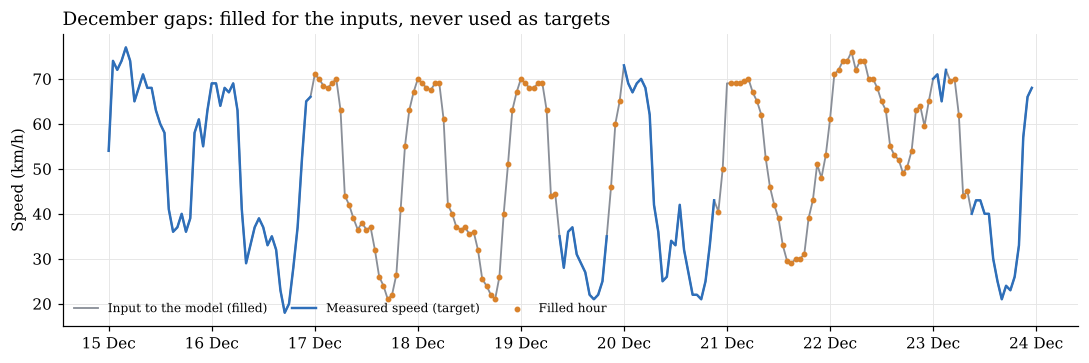

,speed_filled,nb1_filled,nb2_filled,nb3_filled,nb4_filled,nb5_filled,nb6_filled
split,,,,,,,
train,0.096,0.096,0.096,0.097,0.096,0.096,0.096
val,0.001,0.001,0.001,0.001,0.001,0.001,0.001
test,0.147,0.147,0.148,0.148,0.147,0.147,0.146


In [5]:
week=slice('2024-12-15', '2024-12-23')
fig, ax=plt.subplots(figsize=(10, 3.4))
part=df.loc[week]
ax.plot(part.index, part['speed'], color=GREY, lw=1.2, label='Input to the model (filled)')
ax.plot(part.index, part['speed_raw'], color=BLUE, lw=1.6, label='Measured speed (target)')
filled=part.query('speed_filled==1')
ax.scatter(filled.index, filled['speed'], s=8, color=ORANGE, zorder=3, label='Filled hour')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_ylabel('Speed (km/h)')
ax.set_title('December gaps: filled for the inputs, never used as targets', loc='left')
ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left')
fig.tight_layout(); save(fig, 'fig13_gap_filling'); plt.show()

filled_share=df.groupby('split', sort=False)[['speed_filled']+[f'nb{i}_filled' for i in range(1, N_NEIGHBOURS+1)]].mean().round(3)
filled_share

**Findings.** About 10% of training hours and 15% of test hours are filled. The validation period is almost complete.
The filled values follow the usual weekly shape, but they cannot show unusual events, which is why they are never scored.

## 5 · Add weather

We keep **temperature, rain, snowfall and wind speed**. `visibility` is empty in the source, `precipitation` is almost
the same as `rain`, and humidity showed no clear link with speed.

### Which weather can the model use?
To forecast the speed at 18:00, the model runs at 17:00. At that moment the real weather of 18:00 is **not known yet**;
only a weather forecast would be available.

- **If our aim were the highest possible accuracy,** we would give the model the measured weather of 18:00 itself.
  The score would look better, because the model would know exactly when the rain starts. But this information
  does not exist at 17:00 in real life, so the score would be too optimistic.
- **Because our aim is a realistic forecast,** the model only uses weather **up to the hour before** the forecast time
  (the lag is applied in notebook 03). This is the information a traffic centre would really have.

In the paper we can add the "perfect weather forecast" version as a separate experiment, to show how much a good
weather forecast could add. It will not be the main result.

In [6]:
df[WEATHER_COLS].describe().round(2)

,temperature,rain,snowfall,wind_speed
count,8784.00,8784.00,8784.00,8784.00
mean,15.67,0.08,0.00,13.61
std,7.63,0.41,0.02,6.60
min,-3.30,0.00,0.00,0.40
25%,9.90,0.00,0.00,8.40
50%,14.45,0.00,0.00,12.90
75%,21.90,0.00,0.00,18.00
max,34.90,11.70,1.12,39.50


## 6 · Add the Turkish calendar

> 🔍 **Why?** 01 showed strong calendar effects: roads empty at iftar time, the first holiday day behaves like a normal
> day, and the later holiday days are much faster. The calendar is fully known in advance, so it can be used for the
> forecast hour itself without breaking the realism rule.

| Feature | Meaning |
|---|---|
| `is_public_holiday` | Official full-day holiday |
| `is_holiday_day1` | First day of Ramadan or Kurban Bayramı (behaves differently, see 01) |
| `is_half_day` | Eve of a holiday (arife), afternoon only |
| `is_admin_leave` | Extra days off for public employees around the holidays |
| `is_ramadan` | Ramadan month |
| `is_iftar_hour`, `is_after_iftar` | Hour of sunset during Ramadan and the hour after it |
| `is_school_day` | Weekday inside a school term (MEB calendar), not a holiday or school break |

Iftar time is calculated as the **sunset at Mahmutbey** for each day, instead of a fixed "18:00–20:00" window.
During Ramadan 2024 sunset moved from 19:07 to 19:38, so the iftar hour is 19:00 on every day.

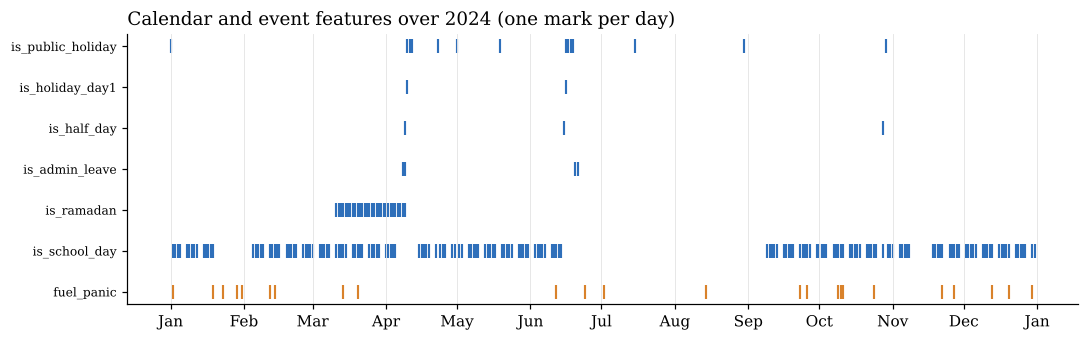

is_public_holiday     336
is_holiday_day1        48
is_half_day            33
is_admin_leave         96
is_ramadan            720
is_school_day        4272
fuel_panic            144
is_iftar_hour          30
is_after_iftar         30


In [7]:
cal_cols=['is_public_holiday', 'is_holiday_day1', 'is_half_day', 'is_admin_leave', 'is_ramadan', 'is_school_day', 'fuel_panic']
daily=df[cal_cols].resample('D').max()

fig, ax=plt.subplots(figsize=(10, 3.2))
for i, col in enumerate(cal_cols):
    days=daily.index[daily[col]==1]
    ax.scatter(days, [i]*len(days), marker='|', s=90, color=ORANGE if col=='fuel_panic' else BLUE, lw=1.4)
ax.set_yticks(range(len(cal_cols))); ax.set_yticklabels(cal_cols, fontsize=8)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Calendar and event features over 2024 (one mark per day)', loc='left')
ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, 'fig14_calendar'); plt.show()

print(df[cal_cols+['is_iftar_hour', 'is_after_iftar']].sum().to_string())

**Sources.** Public holidays: Law No. 2429 and the 2024 religious holiday dates. Administrative leave: Presidential
circulars (8–9 April and 20–21 June 2024). School terms: MEB 2023–24 and 2024–25 calendars. The dates are listed in
`src/calendar_2024.py`.

## 7 · Add fuel price events

The 24 fuel hike nights (144 hours) from `data/raw/fuel_panic_hours_2024.csv` are added as `fuel_panic`. The event is
announced in the news before it happens, so it is known in advance like the calendar. As found in 01, 4 of these nights
have no traffic data, so the effect can only be measured on 20 nights. Its value will be tested in modelling.

## 8 · Save the dataset

In [8]:
out=ROOT/'data'/'processed'
out.mkdir(parents=True, exist_ok=True)
df.to_parquet(out/'dataset.parquet')

print(f'Saved {out/"dataset.parquet"}')
print(f'Shape: {df.shape}')
print(f'Missing values outside the target column: {df.drop(columns="speed_raw").isna().sum().sum()}')
print(f'Target hours (speed_raw not empty): {df["speed_raw"].notna().sum():,}')
print('Columns:', list(df.columns))

Saved /home/claude/mahmutbey-traffic-forecast/data/processed/dataset.parquet
Shape: (8784, 33)
Missing values outside the target column: 0
Target hours (speed_raw not empty): 8,004
Columns: ['split', 'observed', 'suspect', 'usable', 'speed_raw', 'speed', 'speed_filled', 'vehicles', 'nb1_speed', 'nb1_filled', 'nb2_speed', 'nb2_filled', 'nb3_speed', 'nb3_filled', 'nb4_speed', 'nb4_filled', 'nb5_speed', 'nb5_filled', 'nb6_speed', 'nb6_filled', 'temperature', 'rain', 'snowfall', 'wind_speed', 'is_public_holiday', 'is_holiday_day1', 'is_half_day', 'is_admin_leave', 'is_ramadan', 'is_iftar_hour', 'is_after_iftar', 'is_school_day', 'fuel_panic']


## 9 · Summary

| Decision | Choice | Reason |
|---|---|---|
| Split | Train Jan–Aug, validation Sep–Oct, test Nov–Dec; walk-forward inside Jan–Oct for model choice | No leakage, easy to explain, stability check |
| Suspect hours | Vehicles < 10% of typical for that weekday and hour | Removes outage artefacts, keeps real low-traffic hours |
| Neighbours | 6 most correlated cells within 3 km, ≥ 90% coverage, chosen on training data | Clear, repeatable rule |
| Gaps | Filled with training-period weekday × hour median, with a flag | Keeps windows usable; filled values are never scored |
| Weather | Temperature, rain, snowfall, wind; only past hours are used | Realism over a higher score |
| Calendar | Holidays, first holiday day, half days, admin leave, Ramadan, iftar by sunset, school days | Effects seen in 01, known in advance |
| Fuel events | Kept as a flag, value tested later | Known in advance, but only 20 observable nights |

**Next step (03):** build the model features from this table: lags (1, 2, 3, 24, 168 h), rolling statistics,
lagged weather and neighbour features.